In [ ]:
# 🍎 Apple Disease Classification using CNN
#Amir_Afzal


In [1]:
## Step 1: Import Libraries
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.21.0
GPU Available: False


In [2]:
## Step 2: Extract Dataset from ZIP--
# IMPORTANT: Update this path to your ZIP file location
# -----------------------------------------------
ZIP_PATH = "apple_disease_classification.zip"   # <-- Change if needed
EXTRACT_DIR = "./dataset"

# Extract only if not already extracted
if not os.path.exists(EXTRACT_DIR):
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print("Extraction complete!")
else:
    print("Dataset already extracted.")

# Set paths
BASE_DIR   = os.path.join(EXTRACT_DIR, "apple_disease_classification")
TRAIN_DIR  = os.path.join(BASE_DIR, "Train")
TEST_DIR   = os.path.join(BASE_DIR, "Test")

print("\nTrain path:", TRAIN_DIR)
print("Test  path:", TEST_DIR)

Extracting dataset...
Extraction complete!

Train path: ./dataset\apple_disease_classification\Train
Test  path: ./dataset\apple_disease_classification\Test


In [3]:
## Step 3: Explore the Dataset
# List classes
classes = sorted(os.listdir(TRAIN_DIR))
print("Classes:", classes)
NUM_CLASSES = len(classes)
print("Number of classes:", NUM_CLASSES)

# Count images per split
print("\n{:<20} {:>10} {:>10}".format('Class', 'Train', 'Test'))
print("-" * 42)
for cls in classes:
    train_count = len(os.listdir(os.path.join(TRAIN_DIR, cls)))
    test_count  = len(os.listdir(os.path.join(TEST_DIR,  cls)))
    print("{:<20} {:>10} {:>10}".format(cls, train_count, test_count))

Classes: ['Blotch_Apple', 'Normal_Apple', 'Rot_Apple', 'Scab_Apple']
Number of classes: 4

Class                     Train       Test
------------------------------------------
Blotch_Apple                116         30
Normal_Apple                 67         24
Rot_Apple                   114         38
Scab_Apple                   85         28


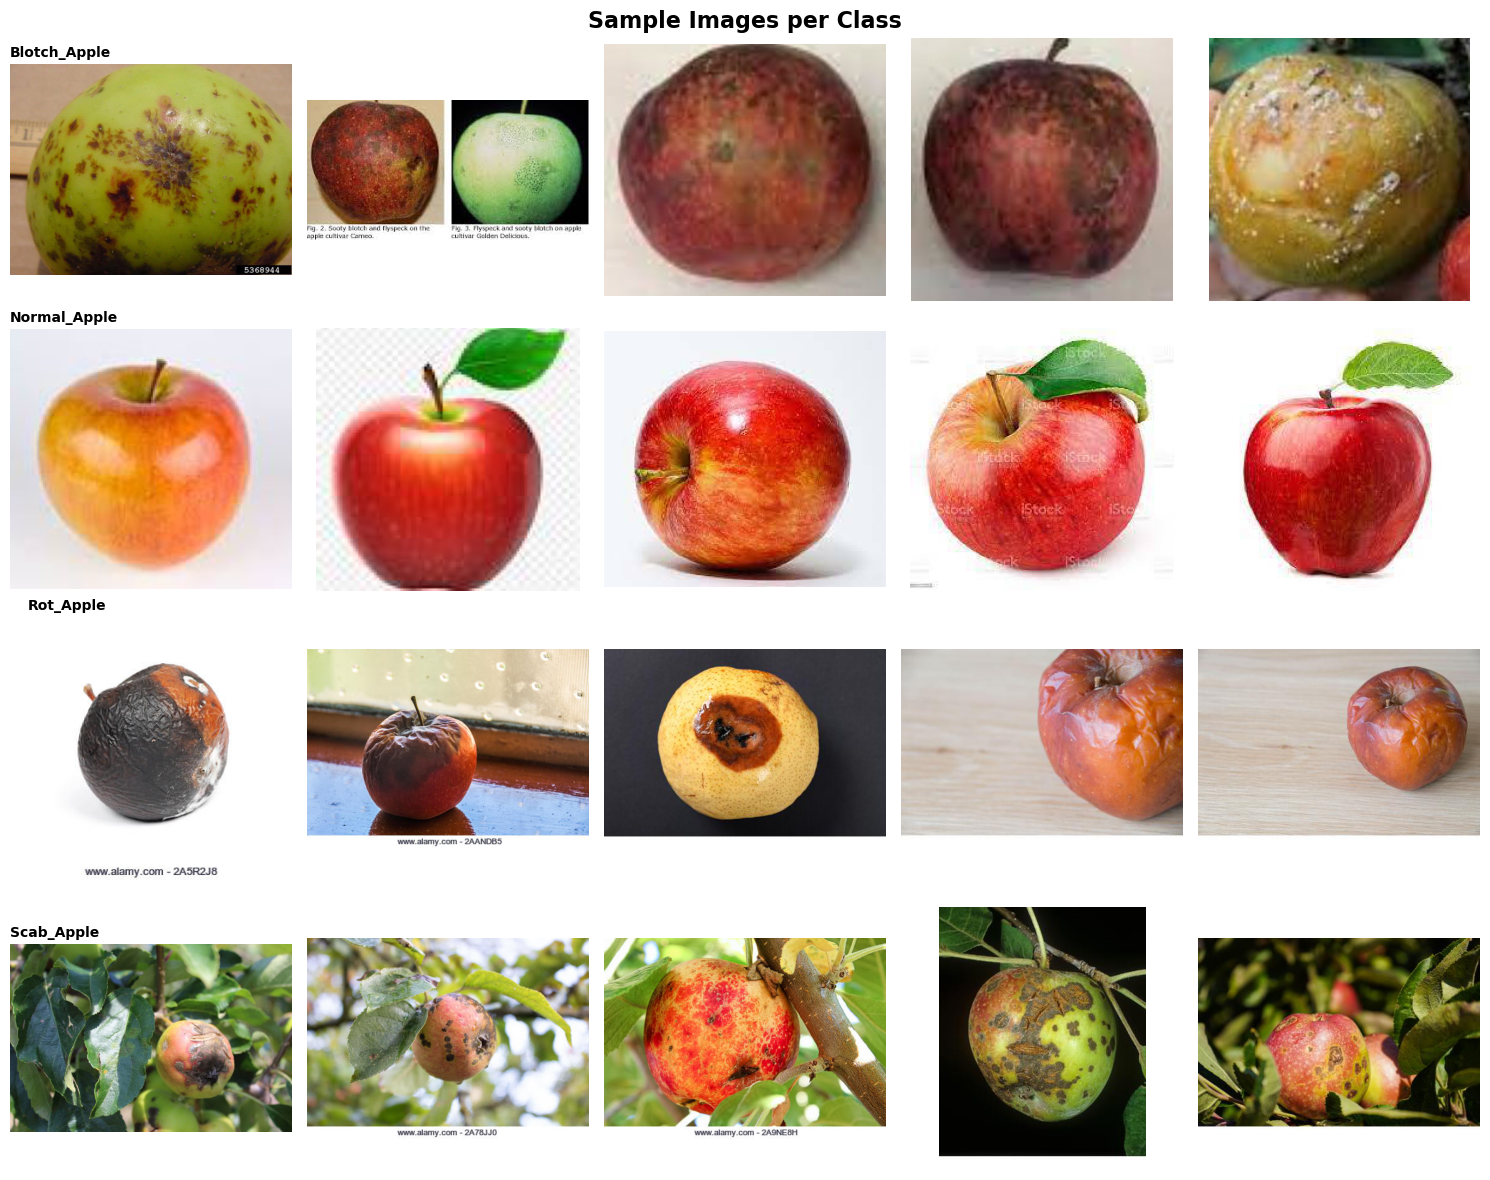

In [4]:
# Visualize sample images from each class
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(15, 3 * NUM_CLASSES))
fig.suptitle('Sample Images per Class', fontsize=16, fontweight='bold')

for row, cls in enumerate(classes):
    cls_path = os.path.join(TRAIN_DIR, cls)
    images   = os.listdir(cls_path)[:5]
    for col, img_name in enumerate(images):
        img = Image.open(os.path.join(cls_path, img_name)).convert('RGB')
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(cls, fontsize=10, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

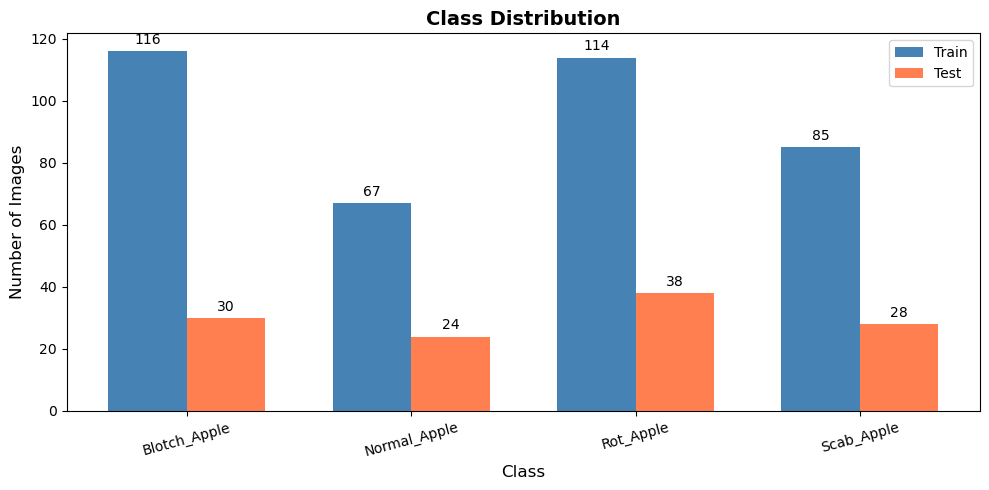

In [5]:
# Class distribution bar chart
train_counts = [len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in classes]
test_counts  = [len(os.listdir(os.path.join(TEST_DIR,  c))) for c in classes]

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, train_counts, width, label='Train', color='steelblue')
bars2 = ax.bar(x + width/2, test_counts,  width, label='Test',  color='coral')

ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Number of Images', fontsize=12)
ax.set_title('Class Distribution', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=15)
ax.legend()
ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)
plt.tight_layout()
plt.show()

In [6]:
## Step 4: Data Preprocessing & Augmentation
# Configuration
IMG_SIZE    = (128, 128)   # Resize all images to 128x128
BATCH_SIZE  = 32
EPOCHS      = 3

# Training generator with augmentation
train_datagen = ImageDataGenerator(
    rescale           = 1./255,        # Normalize pixel values [0,1]
    rotation_range    = 20,            # Random rotation up to 20 degrees
    width_shift_range = 0.2,           # Horizontal shift
    height_shift_range= 0.2,           # Vertical shift
    shear_range       = 0.2,           # Shear transformation
    zoom_range        = 0.2,           # Random zoom
    horizontal_flip   = True,          # Flip horizontally
    fill_mode         = 'nearest',     # Fill missing pixels
    validation_split  = 0.15           # 15% of train as validation
)

# Test generator — only rescale, NO augmentation
test_datagen = ImageDataGenerator(rescale=1./255)

# Load data
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = 'categorical',
    subset       = 'training',
    shuffle      = True
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = 'categorical',
    subset       = 'validation',
    shuffle      = False
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = 'categorical',
    shuffle      = False
)

class_labels = list(train_generator.class_indices.keys())
print("Class labels:", class_labels)

Found 326 images belonging to 4 classes.
Found 56 images belonging to 4 classes.
Found 120 images belonging to 4 classes.
Class labels: ['Blotch_Apple', 'Normal_Apple', 'Rot_Apple', 'Scab_Apple']


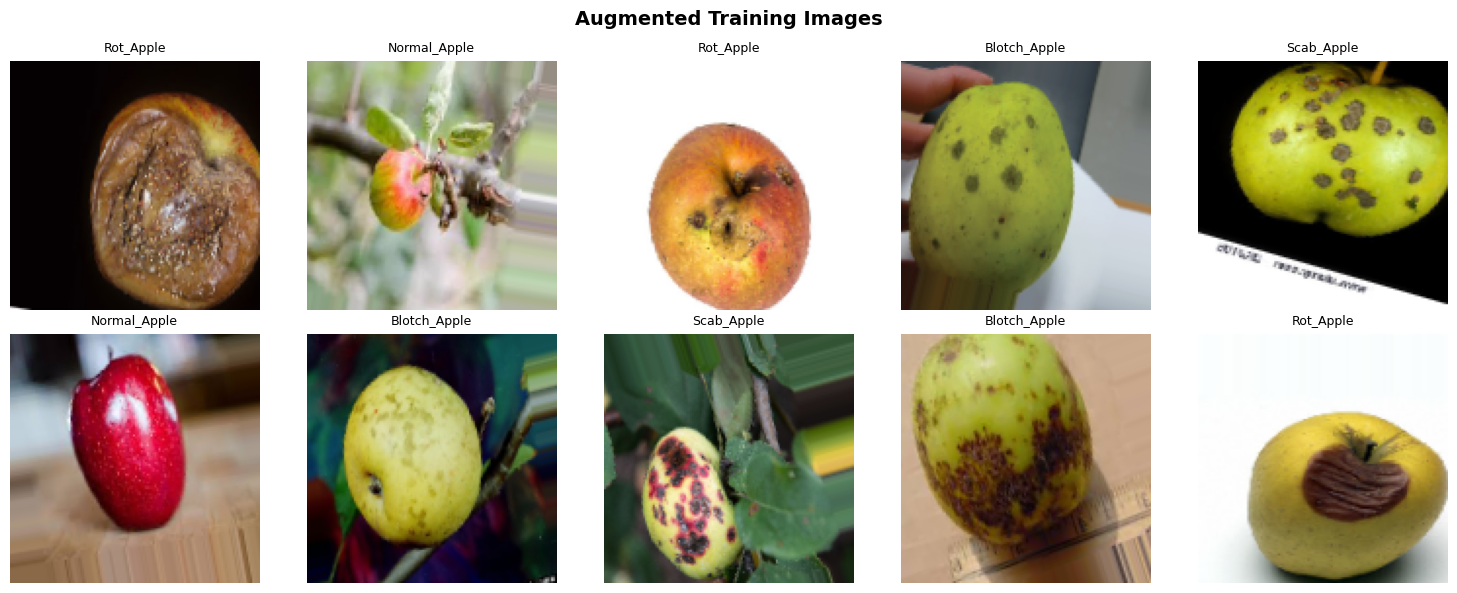

In [7]:
# Visualize augmented images
sample_batch, sample_labels = next(train_generator)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Augmented Training Images', fontsize=14, fontweight='bold')
for i, ax in enumerate(axes.flatten()):
    ax.imshow(sample_batch[i])
    ax.set_title(class_labels[np.argmax(sample_labels[i])], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
## Step 5: Build the CNN Model
def build_cnn_model(input_shape=(128, 128, 3), num_classes=4):
    model = models.Sequential(name='Apple_Disease_CNN')

    # ---- Block 1 ----
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same',
                            input_shape=input_shape, name='conv1_1'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_2'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2), name='pool1'))    # 64x64
    model.add(layers.Dropout(0.25))

    # ---- Block 2 ----
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_1'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_2'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2), name='pool2'))    # 32x32
    model.add(layers.Dropout(0.25))

    # ---- Block 3 ----
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_1'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_2'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2), name='pool3'))    # 16x16
    model.add(layers.Dropout(0.3))

    # ---- Fully Connected Head ----
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation='relu', name='fc1'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(128, activation='relu', name='fc2'))
    model.add(layers.Dropout(0.3))

    # ---- Output Layer ----
    model.add(layers.Dense(num_classes, activation='softmax', name='output'))

    return model

# Build model
model = build_cnn_model(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), num_classes=NUM_CLASSES)
model.summary()

C:\Users\HC\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Apple_Disease_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1_1 (Conv2D)                     │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1_2 (Conv2D)                     │ (None, 128, 128, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2_1 (Conv2D)                     │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2_2 (Conv2D)                     │ (None, 64, 64, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3_1 (Conv2D)                     │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3_2 (Conv2D)                     │ (None, 32, 32, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool3 (MaxPooling2D)                 │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 8,712,100 (33.23 MB)

 Trainable params: 8,710,692 (33.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [9]:
# Optional: visualize model architecture (requires pydot + graphviz)
try:
    tf.keras.utils.plot_model(model, to_file='model_architecture.png',
                               show_shapes=True, show_layer_names=True)
    from IPython.display import Image as IPImage
    IPImage('model_architecture.png')
except Exception as e:
    print("Could not plot model (graphviz may not be installed):", e)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [10]:
## Step 6: Compile the Model
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

print("Model compiled successfully!")
print("Optimizer : Adam (lr=0.001)")
print("Loss      : Categorical Crossentropy")
print("Metrics   : Accuracy")

Model compiled successfully!
Optimizer : Adam (lr=0.001)
Loss      : Categorical Crossentropy
Metrics   : Accuracy


In [11]:
## Step 7: Set Callbacks
# Early stopping — stop training if val_loss doesn't improve
early_stop = EarlyStopping(
    monitor   = 'val_loss',
    patience  = 7,               # Wait 7 epochs before stopping
    restore_best_weights = True,
    verbose   = 1
)

# Save the best model automatically
checkpoint = ModelCheckpoint(
    filepath  = 'best_apple_cnn_model.h5',
    monitor   = 'val_accuracy',
    save_best_only = True,
    verbose   = 1
)

# Reduce learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor   = 'val_loss',
    factor    = 0.5,             # Halve the learning rate
    patience  = 3,
    min_lr    = 1e-6,
    verbose   = 1
)

callbacks = [early_stop, checkpoint, reduce_lr]
print("Callbacks set: EarlyStopping | ModelCheckpoint | ReduceLROnPlateau")

Callbacks set: EarlyStopping | ModelCheckpoint | ReduceLROnPlateau


In [13]:
## Step 8: Train the Model
print("Starting training...\n")

history = model.fit(
    train_generator,
    epochs            = EPOCHS,
    validation_data   = val_generator,
    callbacks         = callbacks,
    verbose           = 1
)

print("\nTraining complete!")

Starting training...

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5307 - loss: 1.2105
Epoch 1: val_accuracy did not improve from 0.30357
11/11 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5552 - loss: 1.1522 - val_accuracy: 0.3036 - val_loss: 2.0905 - learning_rate: 2.5000e-04
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5700 - loss: 1.1074
Epoch 2: val_accuracy did not improve from 0.30357
11/11 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.5706 - loss: 1.1104 - val_accuracy: 0.3036 - val_loss: 2.2349 - learning_rate: 2.5000e-04
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5818 - loss: 1.0273
Epoch 3: val_accuracy did not improve from 0.30357

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
11/11 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.5890 - loss: 1.0087 - val_accuracy: 0.3036 - val_loss: 2.4958 - learning_rate: 2.5000e-04
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6391 - 

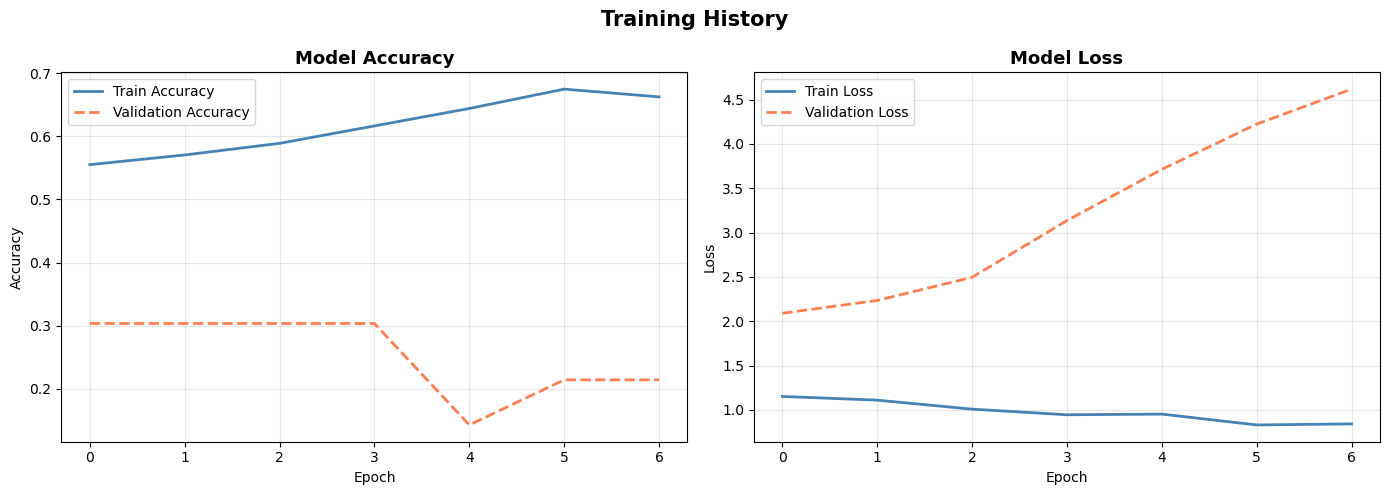

Plot saved as training_curves.png


In [14]:
## Step 9: Plot Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Train Accuracy',      color='steelblue',  linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='coral',      linewidth=2, linestyle='--')
axes[0].set_title('Model Accuracy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'],     label='Train Loss',      color='steelblue',  linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='coral',      linewidth=2, linestyle='--')
axes[1].set_title('Model Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Training History', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved as training_curves.png")

In [15]:
## Step 10: Evaluate on Test Set
# Evaluate overall loss and accuracy
test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f"\n{'='*40}")
print(f"  Test Loss     : {test_loss:.4f}")
print(f"  Test Accuracy : {test_acc * 100:.2f}%")
print(f"{'='*40}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 520ms/step - accuracy: 0.2500 - loss: 2.2372

  Test Loss     : 2.2372
  Test Accuracy : 25.00%


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 368ms/step


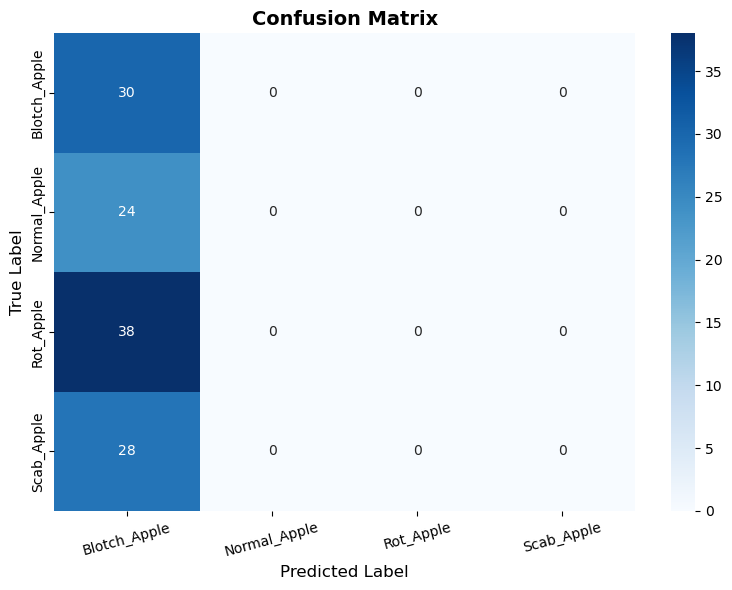

Confusion matrix saved as confusion_matrix.png


In [16]:
## Step 11: Confusion Matrix
# Predict on test set
test_generator.reset()
y_pred_probs = model.predict(test_generator, verbose=1)
y_pred       = np.argmax(y_pred_probs, axis=1)
y_true       = test_generator.classes

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix saved as confusion_matrix.png")

In [17]:
## Step 12: Classification Report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

Classification Report:

              precision    recall  f1-score   support

Blotch_Apple       0.25      1.00      0.40        30
Normal_Apple       0.00      0.00      0.00        24
   Rot_Apple       0.00      0.00      0.00        38
  Scab_Apple       0.00      0.00      0.00        28

    accuracy                           0.25       120
   macro avg       0.06      0.25      0.10       120
weighted avg       0.06      0.25      0.10       120



C:\Users\HC\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HC\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\HC\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 566ms/step


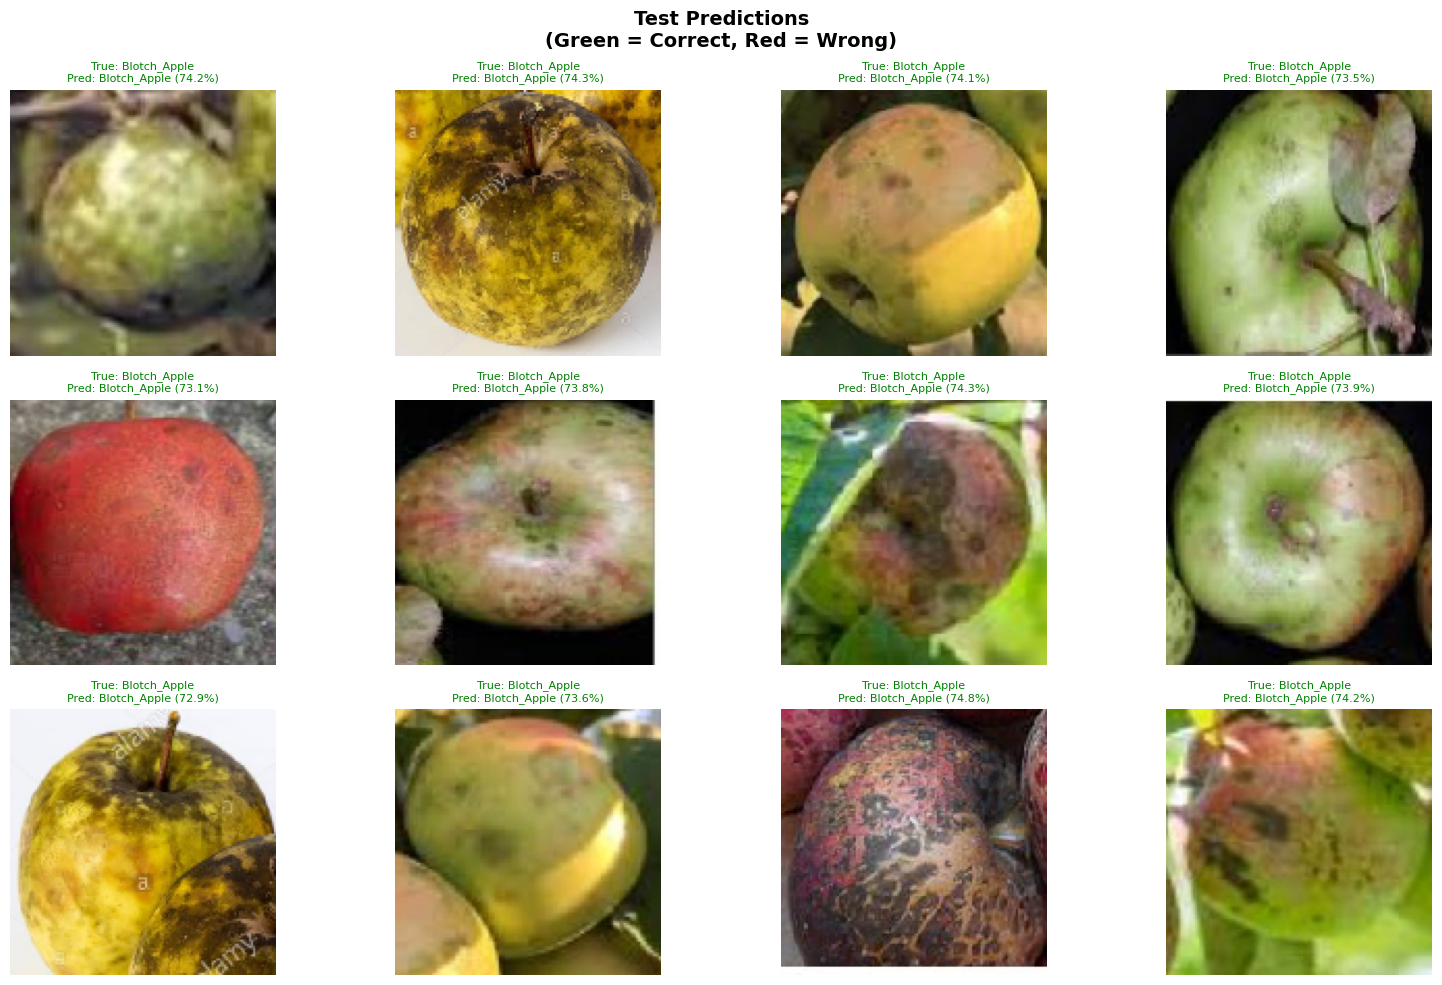

In [18]:
## Step 13: Visualize Predictions on Test Images
# Show 12 test images with their true vs predicted labels
test_generator.reset()
batch_imgs, batch_labels = next(test_generator)

batch_preds = model.predict(batch_imgs)
batch_pred_labels  = np.argmax(batch_preds,  axis=1)
batch_true_labels  = np.argmax(batch_labels, axis=1)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
fig.suptitle('Test Predictions\n(Green = Correct, Red = Wrong)', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flatten()):
    if i >= len(batch_imgs):
        ax.axis('off')
        continue
    ax.imshow(batch_imgs[i])
    true_label = class_labels[batch_true_labels[i]]
    pred_label = class_labels[batch_pred_labels[i]]
    conf       = batch_preds[i][batch_pred_labels[i]] * 100
    color      = 'green' if true_label == pred_label else 'red'
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)",
                 fontsize=8, color=color)
    ax.axis('off')

plt.tight_layout()
plt.savefig('predictions.png', dpi=150, bbox_inches='tight')
plt.show()

Testing on: ./dataset\apple_disease_classification\Test\Blotch_Apple\120.jpg


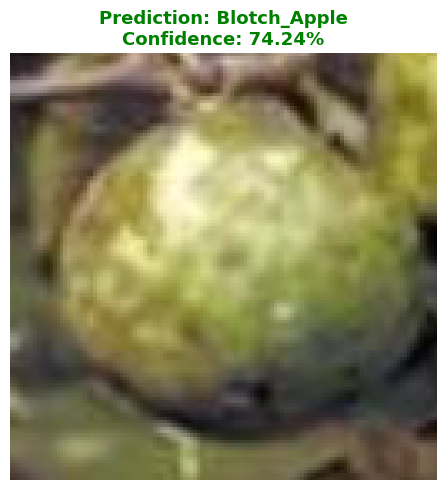


Predicted Class : Blotch_Apple
Confidence      : 74.24%

All class probabilities:
  Blotch_Apple        : 74.24%
  Normal_Apple        : 0.90%
  Rot_Apple           : 7.05%
  Scab_Apple          : 17.81%


('Blotch_Apple', np.float32(74.23682))

In [19]:
## Step 14: Predict a Single New Image
def predict_image(image_path, model, class_labels, img_size=(128, 128)):
    """
    Predict the disease class for a single apple image.
    Args:
        image_path  : path to the image file
        model       : trained Keras model
        class_labels: list of class names
        img_size    : (height, width) expected by model
    """
    # Load and preprocess
    img = Image.open(image_path).convert('RGB').resize(img_size)
    img_array = np.array(img) / 255.0                  # Normalize
    img_array = np.expand_dims(img_array, axis=0)       # Add batch dimension

    # Predict
    preds = model.predict(img_array, verbose=0)[0]
    pred_class = class_labels[np.argmax(preds)]
    confidence = np.max(preds) * 100

    # Display
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {pred_class}\nConfidence: {confidence:.2f}%",
              fontsize=13, fontweight='bold',
              color='green' if confidence > 70 else 'orange')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f"\nPredicted Class : {pred_class}")
    print(f"Confidence      : {confidence:.2f}%")
    print("\nAll class probabilities:")
    for cls, prob in zip(class_labels, preds):
        print(f"  {cls:<20}: {prob*100:.2f}%")

    return pred_class, confidence


# -----------------------------------------------
# Example: predict on a real test image
# Change this path to any apple image you want to test
# -----------------------------------------------
sample_img_path = os.path.join(TEST_DIR, 'Blotch_Apple', os.listdir(os.path.join(TEST_DIR, 'Blotch_Apple'))[0])
print("Testing on:", sample_img_path)
predict_image(sample_img_path, model, class_labels)